In [96]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/sales_data.csv")

df.head()

,Product_ID,Sale_Date,Sales_Rep,Region,Sales_Amount,Quantity_Sold,Product_Category,Unit_Cost,Unit_Price,Customer_Type,Discount,Payment_Method,Sales_Channel,Region_and_Sales_Rep
0,1052,2023-02-03,Bob,North,5053.97,18,Furniture,152.75,267.22,Returning,0.09,Cash,Online,North-Bob
1,1093,2023-04-21,Bob,West,4384.02,17,Furniture,3816.39,4209.44,Returning,0.11,Cash,Retail,West-Bob
2,1015,2023-09-21,David,South,4631.23,30,Food,261.56,371.40,Returning,0.20,Bank Transfer,Retail,South-David
3,1072,2023-08-24,Bob,South,2167.94,39,Clothing,4330.03,4467.75,New,0.02,Credit Card,Retail,South-Bob
4,1061,2023-03-24,Charlie,East,3750.20,13,Electronics,637.37,692.71,New,0.08,Credit Card,Online,East-Charlie


In [97]:
df.shape

(1000, 14)

## 2. Data Inspection

This section examines the structure, data types, summary statistics, missing values, and duplicate records in the sales dataset before analysis.

In [98]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Product_ID            1000 non-null   int64  
 1   Sale_Date             1000 non-null   str    
 2   Sales_Rep             1000 non-null   str    
 3   Region                1000 non-null   str    
 4   Sales_Amount          1000 non-null   float64
 5   Quantity_Sold         1000 non-null   int64  
 6   Product_Category      1000 non-null   str    
 7   Unit_Cost             1000 non-null   float64
 8   Unit_Price            1000 non-null   float64
 9   Customer_Type         1000 non-null   str    
 10  Discount              1000 non-null   float64
 11  Payment_Method        1000 non-null   str    
 12  Sales_Channel         1000 non-null   str    
 13  Region_and_Sales_Rep  1000 non-null   str    
dtypes: float64(4), int64(2), str(8)
memory usage: 109.5 KB


In [99]:
df.describe()

,Product_ID,Sales_Amount,Quantity_Sold,Unit_Cost,Unit_Price,Discount
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000
mean,1050.128000,5019.265230,25.355000,2475.304550,2728.440120,0.15239
std,29.573505,2846.790126,14.159006,1417.872546,1419.399839,0.08720
min,1001.000000,100.120000,1.000000,60.280000,167.120000,0.00000
25%,1024.000000,2550.297500,13.000000,1238.380000,1509.085000,0.08000
50%,1051.000000,5019.300000,25.000000,2467.235000,2696.400000,0.15000
75%,1075.000000,7507.445000,38.000000,3702.865000,3957.970000,0.23000
max,1100.000000,9989.040000,49.000000,4995.300000,5442.150000,0.30000


In [100]:
df.isnull().sum()

Product_ID              0
Sale_Date               0
Sales_Rep               0
Region                  0
Sales_Amount            0
Quantity_Sold           0
Product_Category        0
Unit_Cost               0
Unit_Price              0
Customer_Type           0
Discount                0
Payment_Method          0
Sales_Channel           0
Region_and_Sales_Rep    0
dtype: int64

In [101]:
df.duplicated().sum()

np.int64(0)

In [102]:
df.columns.tolist()

['Product_ID',
 'Sale_Date',
 'Sales_Rep',
 'Region',
 'Sales_Amount',
 'Quantity_Sold',
 'Product_Category',
 'Unit_Cost',
 'Unit_Price',
 'Customer_Type',
 'Discount',
 'Payment_Method',
 'Sales_Channel',
 'Region_and_Sales_Rep']

## 3. Data Cleaning

This section checks for missing values, duplicate records, and inconsistencies to prepare the sales dataset for accurate analysis.

In [103]:
df.isnull().sum()

Product_ID              0
Sale_Date               0
Sales_Rep               0
Region                  0
Sales_Amount            0
Quantity_Sold           0
Product_Category        0
Unit_Cost               0
Unit_Price              0
Customer_Type           0
Discount                0
Payment_Method          0
Sales_Channel           0
Region_and_Sales_Rep    0
dtype: int64

In [104]:
df.duplicated().sum()

np.int64(0)

In [105]:
df.dtypes

Product_ID                int64
Sale_Date                   str
Sales_Rep                   str
Region                      str
Sales_Amount            float64
Quantity_Sold             int64
Product_Category            str
Unit_Cost               float64
Unit_Price              float64
Customer_Type               str
Discount                float64
Payment_Method              str
Sales_Channel               str
Region_and_Sales_Rep        str
dtype: object

In [106]:
df.head(10)

,Product_ID,Sale_Date,Sales_Rep,Region,Sales_Amount,Quantity_Sold,Product_Category,Unit_Cost,Unit_Price,Customer_Type,Discount,Payment_Method,Sales_Channel,Region_and_Sales_Rep
0,1052,2023-02-03,Bob,North,5053.97,18,Furniture,152.75,267.22,Returning,0.09,Cash,Online,North-Bob
1,1093,2023-04-21,Bob,West,4384.02,17,Furniture,3816.39,4209.44,Returning,0.11,Cash,Retail,West-Bob
2,1015,2023-09-21,David,South,4631.23,30,Food,261.56,371.40,Returning,0.20,Bank Transfer,Retail,South-David
3,1072,2023-08-24,Bob,South,2167.94,39,Clothing,4330.03,4467.75,New,0.02,Credit Card,Retail,South-Bob
4,1061,2023-03-24,Charlie,East,3750.20,13,Electronics,637.37,692.71,New,0.08,Credit Card,Online,East-Charlie
5,1021,2023-02-11,Charlie,West,3761.15,32,Food,900.79,1106.51,New,0.21,Cash,Online,West-Charlie
6,1083,2023-04-11,Bob,West,618.31,29,Furniture,2408.81,2624.09,Returning,0.14,Cash,Online,West-Bob
7,1087,2023-01-06,Eve,South,7698.92,46,Furniture,3702.51,3964.65,New,0.12,Bank Transfer,Online,South-Eve
8,1075,2023-06-29,David,South,4223.39,30,Furniture,738.06,1095.45,New,0.05,Bank Transfer,Online,South-David
9,1075,2023-10-09,Charlie,West,8239.58,18,Clothing,2228.35,2682.34,New,0.13,Bank Transfer,Online,West-Charlie


In [107]:
quality_summary = pd.DataFrame({
    "Data Type": df.dtypes.astype(str),
    "Missing Values": df.isnull().sum(),
    "Missing (%)": (df.isnull().mean() * 100).round(2),
    "Unique Values": df.nunique()
})

quality_summary

,Data Type,Missing Values,Missing (%),Unique Values
Product_ID,int64,0,0.0,100
Sale_Date,str,0,0.0,340
Sales_Rep,str,0,0.0,5
Region,str,0,0.0,4
Sales_Amount,float64,0,0.0,998
Quantity_Sold,int64,0,0.0,49
Product_Category,str,0,0.0,4
Unit_Cost,float64,0,0.0,998
Unit_Price,float64,0,0.0,1000
Customer_Type,str,0,0.0,2


In [108]:
print("Duplicate rows:", df.duplicated().sum())
print("Dataset shape:", df.shape)

Duplicate rows: 0
Dataset shape: (1000, 14)


In [109]:
print("Dataset shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
print("\nMissing values per column:")
print(df.isnull().sum())

Dataset shape: (1000, 14)
Duplicate rows: 0

Missing values per column:
Product_ID              0
Sale_Date               0
Sales_Rep               0
Region                  0
Sales_Amount            0
Quantity_Sold           0
Product_Category        0
Unit_Cost               0
Unit_Price              0
Customer_Type           0
Discount                0
Payment_Method          0
Sales_Channel           0
Region_and_Sales_Rep    0
dtype: int64


In [110]:
df.dtypes

Product_ID                int64
Sale_Date                   str
Sales_Rep                   str
Region                      str
Sales_Amount            float64
Quantity_Sold             int64
Product_Category            str
Unit_Cost               float64
Unit_Price              float64
Customer_Type               str
Discount                float64
Payment_Method              str
Sales_Channel               str
Region_and_Sales_Rep        str
dtype: object

In [111]:
df.head()

,Product_ID,Sale_Date,Sales_Rep,Region,Sales_Amount,Quantity_Sold,Product_Category,Unit_Cost,Unit_Price,Customer_Type,Discount,Payment_Method,Sales_Channel,Region_and_Sales_Rep
0,1052,2023-02-03,Bob,North,5053.97,18,Furniture,152.75,267.22,Returning,0.09,Cash,Online,North-Bob
1,1093,2023-04-21,Bob,West,4384.02,17,Furniture,3816.39,4209.44,Returning,0.11,Cash,Retail,West-Bob
2,1015,2023-09-21,David,South,4631.23,30,Food,261.56,371.40,Returning,0.20,Bank Transfer,Retail,South-David
3,1072,2023-08-24,Bob,South,2167.94,39,Clothing,4330.03,4467.75,New,0.02,Credit Card,Retail,South-Bob
4,1061,2023-03-24,Charlie,East,3750.20,13,Electronics,637.37,692.71,New,0.08,Credit Card,Online,East-Charlie


In [112]:
df["Sale_Date"] = pd.to_datetime(df["Sale_Date"], errors="coerce")

In [113]:
df["Sale_Date"].dtype

dtype('<M8[us]')

In [114]:
df["Sale_Date"].isnull().sum()

np.int64(0)

In [115]:
df["Sale_Date"].isnull().sum()

np.int64(0)

## 3. Calculate our sales KPIs

In [116]:
total_revenue = df["Sales_Amount"].sum()
average_sales = df["Sales_Amount"].mean()
total_quantity = df["Quantity_Sold"].sum()
total_transactions = len(df)

print(f"Total Revenue: R{total_revenue:,.2f}")
print(f"Average Sales Amount: R{average_sales:,.2f}")
print(f"Total Quantity Sold: {total_quantity:,}")
print(f"Total Transactions: {total_transactions:,}")

Total Revenue: R5,019,265.23
Average Sales Amount: R5,019.27
Total Quantity Sold: 25,355
Total Transactions: 1,000


## 4. Sales Performance Analysis

This section evaluates sales performance across regions and product categories to identify the strongest contributors to sales.

In [117]:
region_sales = (
    df.groupby("Region")["Sales_Amount"]
    .sum()
    .sort_values(ascending=False)
)

region_sales

Region
North    1369612.51
East     1259792.93
West     1235608.93
South    1154250.86
Name: Sales_Amount, dtype: float64

In [118]:
category_sales = (
    df.groupby("Product_Category")["Sales_Amount"]
    .sum()
    .sort_values(ascending=False)
)

category_sales

Product_Category
Clothing       1313474.36
Furniture      1260517.69
Electronics    1243499.64
Food           1201773.54
Name: Sales_Amount, dtype: float64

In [119]:
top_reps = (
    df.groupby("Sales_Rep")["Sales_Amount"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_reps

Sales_Rep
David      1141737.36
Bob        1080990.63
Eve         970183.99
Alice       965541.77
Charlie     860811.48
Name: Sales_Amount, dtype: float64

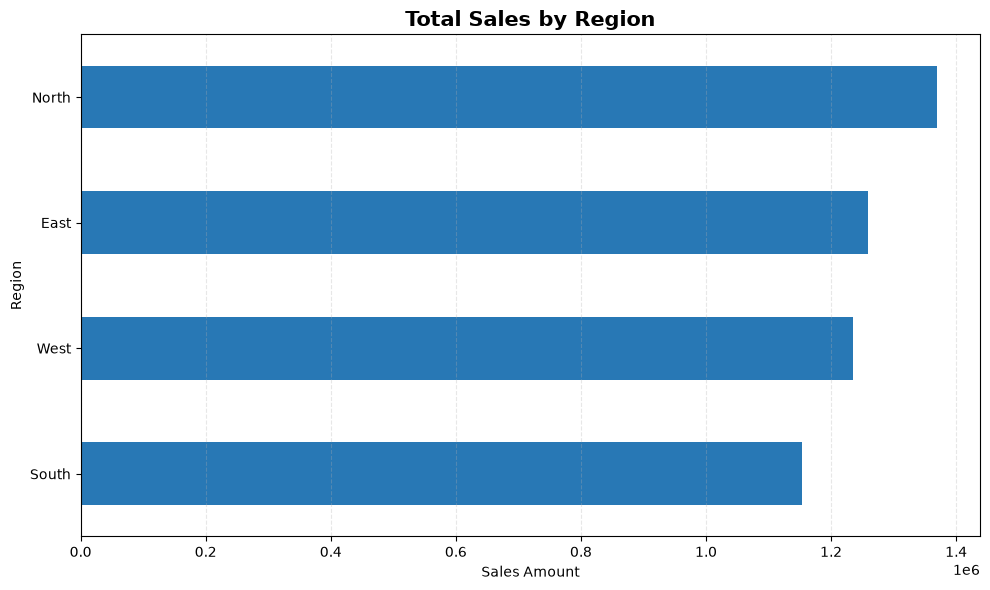

In [120]:
plt.figure(figsize=(10, 6))

region_sales.sort_values().plot(
    kind="barh",
    color="#2878B5"
)

plt.title("Total Sales by Region", fontsize=15, fontweight="bold")
plt.xlabel("Sales Amount")
plt.ylabel("Region")
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Monthly Sales Trends

This section examines monthly sales performance to identify periods of higher and lower sales activity.

In [121]:
monthly_sales = (
    df.set_index("Sale_Date")["Sales_Amount"]
    .resample("MS")
    .sum()
)

monthly_sales

Sale_Date
2023-01-01    476092.36
2023-02-01    368919.36
2023-03-01    402638.77
2023-04-01    438992.61
2023-05-01    389078.76
2023-06-01    418458.34
2023-07-01    374242.88
2023-08-01    443171.28
2023-09-01    367837.60
2023-10-01    460378.78
2023-11-01    467482.90
2023-12-01    392643.58
2024-01-01     19328.01
Freq: MS, Name: Sales_Amount, dtype: float64

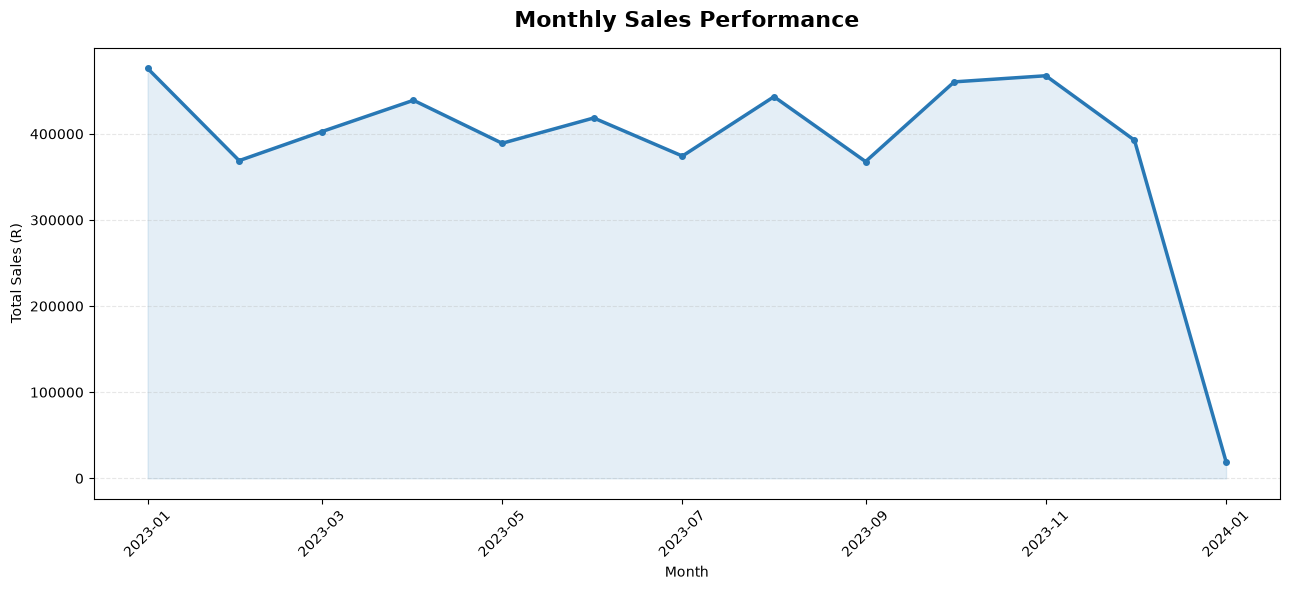

In [122]:
plt.figure(figsize=(13, 6))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    color="#2878B5",
    linewidth=2.5,
    marker="o",
    markersize=4
)

plt.fill_between(
    monthly_sales.index,
    monthly_sales.values,
    alpha=0.12,
    color="#2878B5"
)

plt.title(
    "Monthly Sales Performance",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel("Month")
plt.ylabel("Total Sales (R)")

plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.xticks(rotation=45)
plt.ticklabel_format(axis="y", style="plain")
plt.tight_layout()
plt.show()

In [123]:
best_month = monthly_sales.idxmax()
worst_month = monthly_sales.idxmin()

print("Highest sales month:", best_month.strftime("%B %Y"))
print(f"Highest monthly sales: R{monthly_sales.max():,.2f}")

print("Lowest sales month:", worst_month.strftime("%B %Y"))
print(f"Lowest monthly sales: R{monthly_sales.min():,.2f}")

Highest sales month: January 2023
Highest monthly sales: R476,092.36
Lowest sales month: January 2024
Lowest monthly sales: R19,328.01


## 6. Top Selling Products

In [124]:
top_products = (
    df.groupby("Product_ID")["Sales_Amount"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products

Product_ID
1099    101773.87
1092     90615.62
1033     89130.41
1090     88043.25
1086     82269.71
1089     82055.13
1048     81496.82
1001     81017.34
1062     76696.76
1024     75136.67
Name: Sales_Amount, dtype: float64

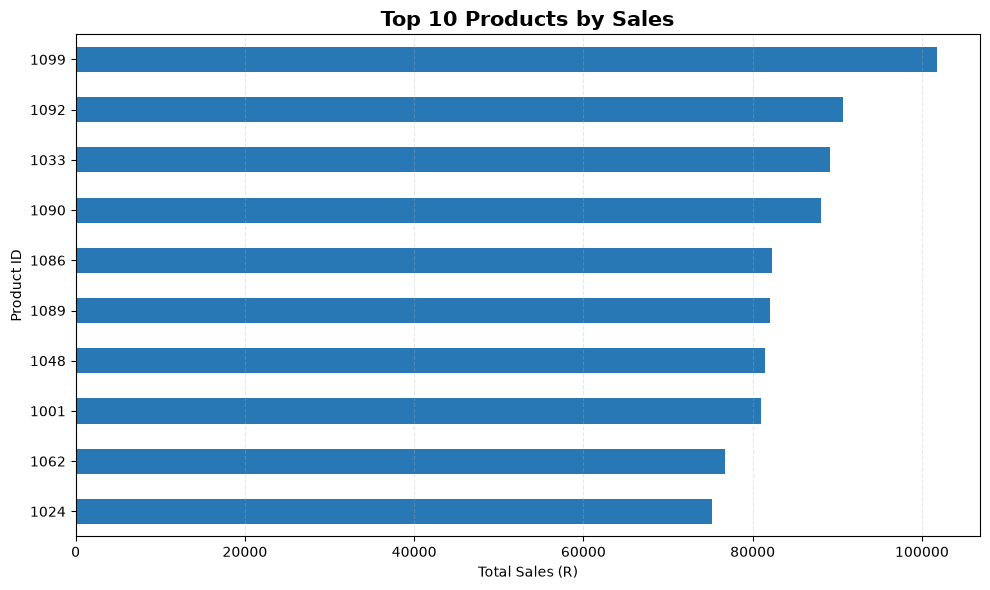

In [125]:
plt.figure(figsize=(10, 6))

top_products.sort_values().plot(
    kind="barh",
    color="#2878B5"
)

plt.title("Top 10 Products by Sales", fontsize=15, fontweight="bold")
plt.xlabel("Total Sales (R)")
plt.ylabel("Product ID")
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.ticklabel_format(axis="x", style="plain")
plt.tight_layout()
plt.show()

## 7. Sales performance by representative

In [126]:
sales_rep_performance = (
    df.groupby("Sales_Rep")["Sales_Amount"]
    .sum()
    .sort_values(ascending=False)
)

sales_rep_performance.head(10)

Sales_Rep
David      1141737.36
Bob        1080990.63
Eve         970183.99
Alice       965541.77
Charlie     860811.48
Name: Sales_Amount, dtype: float64

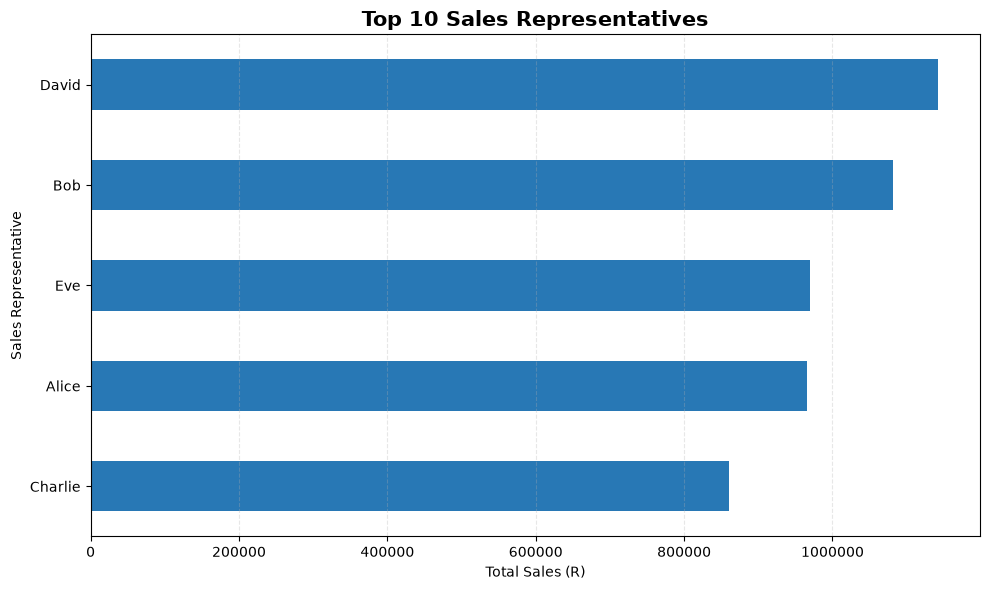

In [127]:
plt.figure(figsize=(10, 6))

sales_rep_performance.head(10).sort_values().plot(
    kind="barh",
    color="#2878B5"
)

plt.title("Top 10 Sales Representatives", fontsize=15, fontweight="bold")
plt.xlabel("Total Sales (R)")
plt.ylabel("Sales Representative")
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.ticklabel_format(axis="x", style="plain")
plt.tight_layout()
plt.show()

## 8. business insights

In [128]:
# Top-performing region
best_region = region_sales.idxmax()
best_region_sales = region_sales.max()

# Top-performing product category
best_category = category_sales.idxmax()
best_category_sales = category_sales.max()

# Top-performing sales representative
best_rep = sales_rep_performance.idxmax()
best_rep_sales = sales_rep_performance.max()

# Highest and lowest sales months
best_month = monthly_sales.idxmax()
worst_month = monthly_sales.idxmin()

print(f"Top Region: {best_region} — R{best_region_sales:,.2f}")
print(f"Top Category: {best_category} — R{best_category_sales:,.2f}")
print(f"Top Sales Representative: {best_rep} — R{best_rep_sales:,.2f}")
print(f"Best Month: {best_month.strftime('%B %Y')} — R{monthly_sales.max():,.2f}")
print(f"Weakest Month: {worst_month.strftime('%B %Y')} — R{monthly_sales.min():,.2f}")

Top Region: North — R1,369,612.51
Top Category: Clothing — R1,313,474.36
Top Sales Representative: David — R1,141,737.36
Best Month: January 2023 — R476,092.36
Weakest Month: January 2024 — R19,328.01


In [129]:
print("First sale date:", df["Sale_Date"].min())
print("Last sale date:", df["Sale_Date"].max())
print("\nTransactions by month:")
print(df.groupby(df["Sale_Date"].dt.to_period("M")).size())

First sale date: 2023-01-01 00:00:00
Last sale date: 2024-01-01 00:00:00

Transactions by month:
Sale_Date
2023-01    100
2023-02     75
2023-03     80
2023-04     81
2023-05     72
2023-06     92
2023-07     68
2023-08     93
2023-09     68
2023-10     88
2023-11     95
2023-12     85
2024-01      3
Freq: M, dtype: int64
